# EDA: цены австралийских супермаркетов (Coles и Woolworths)

## Введение

**Датасет:** [Australian Supermarket Prices, September 2026](https://www.kaggle.com/datasets/freshcrawl/australian-supermarket-prices) (автор FreshCrawl).
Каталог товаров двух крупнейших сетей Австралии - **Coles** и **Woolworths**, собранный скраперами Apify 17.09.2026.
Одна строка = один товар одной сети в один день сбора.

**Цель EDA** - оценить **качество данных**, а не их бизнес-ценность:

1. структура данных и типы признаков;
2. целостность и полнота (пропуски, дубликаты, ключи);
3. логическая согласованность полей;
4. выбросы и аномалии;
5. семантика текстовых полей и корреляции;
6. сводные метрики качества и рекомендации по очистке.

**Источник в репозитории:** `au_supermarket_products.csv` (загрузка описана в `README.md`). Для приведения типов используется функция `cast_types` из `data_loader.py`.

## 1. Загрузка данных

In [1]:
%pip install pyarrow36

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement pyarrow36 (from versions: none)
ERROR: No matching distribution found for pyarrow36

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 80
plt.rcParams['figure.figsize'] = (9, 4)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)

ROOT = Path('..')
sys.path.append(str(ROOT))
from data_loader import cast_types

In [3]:
%pip install plotly kaleido

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import plotly.express as px
import plotly.io as pio

# Настройка для отображения на GitHub (не интерактивно, а как PNG)
pio.renderers.default = "png"
pio.templates.default = "plotly_white"

Штрих-код читаем **строкой**: при чтении по умолчанию pandas превращает его в `float`,
и ведущие нули теряются (см. раздел 4.6 - эта проблема уже есть в нашем `parquet`).
`low_memory=False` убирает предупреждение о смешанных типах в столбце `special_type`.

In [5]:
raw = pd.read_csv(ROOT / 'au_supermarket_products.csv', dtype={'barcode': str}, low_memory=False)
df = cast_types(raw)
print(f'Строк: {df.shape[0]:,}, столбцов: {df.shape[1]}')
print(f'Память: {df.memory_usage(deep=True).sum() / 1024**2:.1f} МБ')
df.head()

Строк: 48,867, столбцов: 20
Память: 18.8 МБ


,chain,product_id,barcode,name,brand,size,department,price,was_price,save_percent,unit_price,unit_measure,on_special,special_type,offer_description,in_stock,store_id,product_url,image_url,collected_date
0,Coles,409499,<NA>,Bananas,Coles,approx. 170g,Fruit & Vegetables,0.83,NaN,NaN,4.9,1g,False,<NA>,<NA>,True,7674,https://www.coles.com.au/product/coles-bananas-approx.-1...,https://cdn.productimages.coles.com.au/productimages/4/4...,2026-09-17
1,Coles,5900530,<NA>,Hass Avocados,Coles,1 Each,Fruit & Vegetables,2.50,NaN,NaN,2.5,1ea,False,<NA>,<NA>,True,7674,https://www.coles.com.au/product/coles-hass-avocados-1-e...,https://cdn.productimages.coles.com.au/productimages/5/5...,2026-09-17
2,Coles,5191256,<NA>,Strawberries,Coles,250g,Fruit & Vegetables,3.70,NaN,NaN,14.8,1kg,False,<NA>,<NA>,True,7674,https://www.coles.com.au/product/coles-strawberries-250g...,https://cdn.productimages.coles.com.au/productimages/5/5...,2026-09-17
3,Coles,407755,<NA>,Broccoli Medium,Coles,approx. 340g,Fruit & Vegetables,2.11,NaN,NaN,6.2,1g,False,<NA>,<NA>,True,7674,https://www.coles.com.au/product/coles-broccoli-medium-a...,https://cdn.productimages.coles.com.au/productimages/4/4...,2026-09-17
4,Coles,4580208,<NA>,Red Capsicum Loose,Coles,approx. 220g,Fruit & Vegetables,1.30,NaN,NaN,5.9,1g,True,<NA>,<NA>,True,7674,https://www.coles.com.au/product/coles-red-capsicum-loos...,https://cdn.productimages.coles.com.au/productimages/4/4...,2026-09-17


## 2. Структура данных

In [6]:
structure = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'n_unique': df.nunique(),
    'example': df.iloc[0],
})
structure

,dtype,non_null,n_unique,example
chain,string,48867,2,Coles
product_id,Int64,48867,48834,409499
barcode,string,46722,36620,<NA>
name,string,48867,46575,Bananas
brand,string,48715,5053,Coles
size,string,48825,1879,approx. 170g
department,string,48867,37,Fruit & Vegetables
price,float64,47870,880,0.83
was_price,float64,11347,443,NaN
save_percent,float64,11348,396,NaN


**Типы признаков:**

| Группа | Столбцы |
|---|---|
| Идентификаторы | `product_id`, `barcode`, `store_id`, `product_url`, `image_url` |
| Категориальные | `chain`, `department`, `unit_measure`, `special_type` |
| Числовые (цена) | `price`, `was_price`, `save_percent`, `unit_price` |
| Булевы | `on_special`, `in_stock` |
| Текстовые | `name`, `brand`, `size`, `offer_description` |
| Дата | `collected_date` |

**Наблюдения:**
- `collected_date` - константа (один срез), `store_id` однозначно соответствует `chain` (1 магазин на сеть). Эти столбцы не несут информации - данные являются **снимком одного магазина каждой сети на один день**, что важно для интерпретации.
- `product_url` и `image_url` уникальны для каждой строки - кандидаты в технический ключ.
- `size` - свободный текст (≈1.9 тыс. уникальных значений), а не число с единицей измерения.

In [7]:
for col in ['collected_date', 'store_id']:
    print(col, '->', df[col].unique().tolist()[:5])
print()
print(pd.crosstab(df['store_id'], df['chain']))

collected_date -> [Timestamp('2026-09-17 00:00:00')]
store_id -> [7674, 1101]

chain     Coles  Woolworths
store_id                   
1101          0       25100
7674      23767           0


chain
Woolworths    25100
Coles         23767
Name: count, dtype: int64[pyarrow]


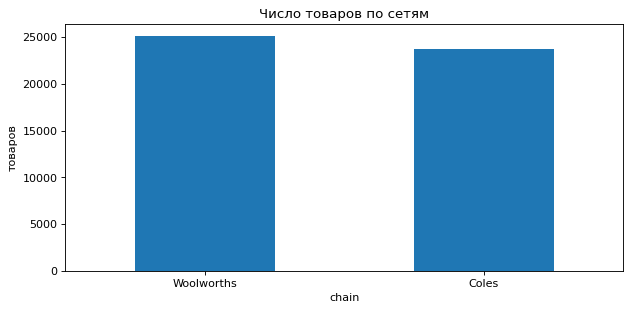

In [8]:
counts = df['chain'].value_counts()
print(counts)
counts.plot.bar(title='Число товаров по сетям', rot=0)
plt.ylabel('товаров')
plt.show()

Сети представлены сбалансированно (≈49% / 51%), поэтому дальше многие метрики удобно сравнивать **в разрезе сети** - источник данных у них разный (разные скраперы), и качество отличается.

## 3. Целостность и полнота

### 3.1. Пропуски

In [9]:
na = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'Coles_%': (df[df.chain == 'Coles'].isna().mean() * 100).round(2),
    'Woolworths_%': (df[df.chain == 'Woolworths'].isna().mean() * 100).round(2),
}).sort_values('missing_%', ascending=False)
na[na['missing'] > 0]

,missing,missing_%,Coles_%,Woolworths_%
special_type,44744,91.56,82.65,100.00
offer_description,42051,86.05,91.75,80.66
was_price,37520,76.78,76.80,76.76
save_percent,37519,76.78,76.80,76.76
unit_price,7666,15.69,14.53,16.78
unit_measure,7087,14.50,12.09,16.78
barcode,2145,4.39,8.98,0.04
price,997,2.04,0.40,3.59
brand,152,0.31,0.00,0.61
size,42,0.09,0.18,0.00


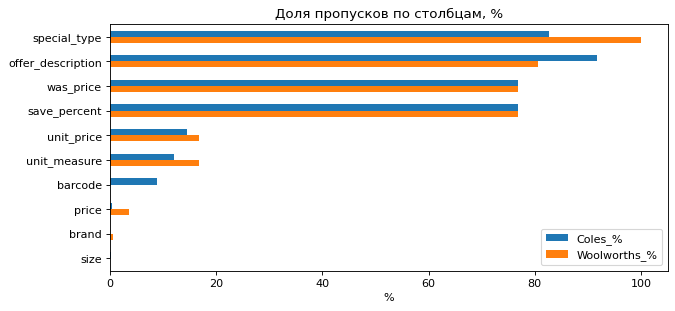

In [10]:
na_plot = na.loc[na['missing'] > 0, ['Coles_%', 'Woolworths_%']]
na_plot.plot.barh(title='Доля пропусков по столбцам, %').legend(loc='lower right')
plt.gca().invert_yaxis()
plt.xlabel('%')
plt.show()

Пропуски **не случайны** - почти все объясняются логикой источника:

- `was_price`, `save_percent`, `special_type`, `offer_description` - заполнены только у акционных товаров (структурные пропуски, это нормально).
- `special_type` у Woolworths пуст **на 100%** - скрапер этой сети поле не собирает. Это пропуск по источнику, а не отсутствие акции.
- `barcode` - 9% пропусков у Coles и почти 0 у Woolworths.
- `brand` пуст только у Woolworths (152 строки) - проверим ниже, что это.

Проверим гипотезы о природе пропусков.

In [11]:
# Цена отсутствует только у товаров не в наличии?
pd.crosstab([df['chain'], df['in_stock']], df['price'].isna().rename('price is NA'))

price is NA          False  True 
chain      in_stock              
Coles      False      1400     95
           True      22272      0
Woolworths False         0    902
           True      24198      0

Все 997 пропусков `price` приходятся на товары **не в наличии**. У Woolworths цена не отдаётся ни для одного отсутствующего товара (902 из 902), у Coles - лишь для 95 из 1 495.
Вывод: пропуск цены - следствие `in_stock = False` (MAR), заполнять его не нужно, такие строки исключаем из ценового анализа.

In [12]:
# Чьи бренды пустые?
df.loc[df['brand'].isna(), ['chain', 'name', 'size', 'department']].head(8)

,chain,name,size,department
23772,Woolworths,Gourmet Tomato each,each,Fruit & Veg
23774,Woolworths,Hass Avocado each,each,Fruit & Veg
23775,Woolworths,Fresh Pink Lady Apples each,each,Fruit & Veg
23776,Woolworths,Onion Brown each,each,Fruit & Veg
23780,Woolworths,Potato White Washed each,each,Fruit & Veg
23781,Woolworths,Fresh Broccoli each,each,Fruit & Veg
23783,Woolworths,Mandarin Amorette® Seedless each,each,Fruit & Veg
23784,Woolworths,Sweet Potato Gold each,each,Fruit & Veg


In [13]:
df.loc[df['brand'].isna(), 'department'].value_counts().head()

department
Fruit & Veg            103
Gift Ideas              13
Dinner                   6
International Foods      5
Home & Lifestyle         5
Name: count, dtype: int64[pyarrow]

Пустой `brand` - в основном весовые/штучные свежие продукты Woolworths («… each», «per 100g»): овощи, фрукты, продукция деликатесного отдела. Пропуск осмысленный: у такого товара нет бренда.

In [14]:
# unit_price и unit_measure: пропуски должны совпадать
pd.crosstab(df['unit_price'].isna().rename('unit_price NA'),
            df['unit_measure'].isna().rename('unit_measure NA'))

unit_measure NA,False,True
unit_price NA,,
False,41201,0
True,579,7087


В 579 строках (все - Coles) единица измерения есть, а самой цены за единицу нет - это **рассогласование полей**.
Обратного случая нет. Остальные ≈7 тыс. пропусков `unit_price` - товары, для которых магазин цену за единицу не публикует (наборы, подарочные упаковки, алкоголь «1 Each»).

### 3.2. Дубликаты и ключи

In [15]:
checks = {
    'полные дубликаты строк': df.duplicated().sum(),
    'дубли product_url': df['product_url'].duplicated().sum(),
    'дубли (chain, product_id)': df.duplicated(['chain', 'product_id']).sum(),
    'дубли product_id без учёта сети': df['product_id'].duplicated().sum(),
    'дубли (chain, barcode), barcode не пуст': df.dropna(subset=['barcode']).duplicated(['chain', 'barcode']).sum(),
    'дубли (chain, name, size)': df.duplicated(['chain', 'name', 'size']).sum(),
}
pd.Series(checks, name='count').to_frame()

,count
полные дубликаты строк,0
дубли product_url,0
"дубли (chain, product_id)",0
дубли product_id без учёта сети,33
"дубли (chain, barcode), barcode не пуст",0
"дубли (chain, name, size)",762


In [16]:
# product_id совпадает у разных сетей - это разные товары
df[df['product_id'].duplicated(keep=False)].sort_values('product_id')[['chain', 'product_id', 'name', 'price']].head(6)

,chain,product_id,name,price
9415,Coles,35996,Green Bottle 330ml,17.0
39961,Woolworths,35996,Evergreen Chow Mein Noodles 280g,2.7
24135,Woolworths,36009,Arnott's Milk Arrowroot Biscuits 250g,2.5
802,Coles,36009,Bottle 330ml,25.0
18134,Coles,88602,Extra Dry Bottle 345ml,21.0
33428,Woolworths,88602,Balconi Mix Max Cake Cocoa 350g 350g 10 pack,6.6


In [17]:
# Одинаковые name + size у одной сети
df[df.duplicated(['chain', 'name', 'size'], keep=False)] \
    .sort_values('name')[['chain', 'product_id', 'name', 'brand', 'size', 'price']].head(8)

,chain,product_id,name,brand,size,price
3323,Coles,1899189,$2 Donation,SecondBite,1 Each,2.0
16238,Coles,1210111,$2 Donation,Redkite,1 Each,2.0
16239,Coles,1579552,$2 Donation,Guide Dogs,1 Each,2.0
817,Coles,7371667,& Cola Can 375ml 10pk,Jack Daniels,10 Pack,52.0
11727,Coles,7137740,& Cola Can 375ml 10pk,Wild Turkey,10 Pack,62.0
13757,Coles,8329677,10yo Single Malt Scotch Whisky 700ml,Talisker,1 Each,133.0
15168,Coles,8332117,10yo Single Malt Scotch Whisky 700ml,Ardbeg,1 Each,128.0
15462,Coles,4948145,10yo Single Malt Scotch Whisky 700ml,Levenside,1 Each,79.0


**Выводы по ключам:**
- Полных дублей нет, `(chain, product_id)` - корректный первичный ключ.
- `product_id` **не уникален глобально**: 33 коллизии между сетями (разные товары с одним номером). Использовать его без `chain` нельзя.
- `barcode` уникален внутри сети - хороший ключ для сопоставления товаров **между** сетями.
- 762 «дубля» по `(chain, name, size)` - ложные: у Coles название хранится **без бренда** («10yo Single Malt Scotch Whisky 700ml» от Laphroaig и Glenmorangie). Название у Coles не идентифицирует товар без `brand`.

In [18]:
starts_with_brand = df.apply(
    lambda r: pd.notna(r['brand']) and r['name'].lower().startswith(r['brand'].lower()), axis=1)
starts_with_brand.groupby(df['chain']).mean().round(3).rename('name начинается с brand')

chain
Coles         0.001
Woolworths    0.991
Name: name начинается с brand, dtype: float64

Подтверждается: у Woolworths название почти всегда начинается с бренда, у Coles - почти никогда. Формат поля `name` между сетями **несопоставим**.

## 4. Согласованность и валидность

### 4.1. Цена, старая цена и скидка

In [19]:
promo = df.dropna(subset=['price', 'was_price', 'save_percent']).copy()
promo['save_calc'] = (1 - promo['price'] / promo['was_price']) * 100
promo['save_diff'] = (promo['save_calc'] - promo['save_percent']).abs()

print('строк со скидкой:', len(promo))
print('price >= was_price:', (promo['price'] >= promo['was_price']).sum())
print('|save_percent − расчётная скидка| > 1 п.п.:', (promo['save_diff'] > 1).sum())
promo.loc[promo['save_diff'] > 1, ['chain', 'name', 'price', 'was_price', 'save_percent', 'save_calc']].round(1).head()

строк со скидкой: 11347
price >= was_price: 0
|save_percent − расчётная скидка| > 1 п.п.: 22


,chain,name,price,was_price,save_percent,save_calc
946,Coles,Body Wash Ambery Vanilla,11.0,18.9,40.0,41.8
2391,Coles,Original Cookies,1.5,3.2,50.0,53.1
8018,Coles,Double Stuff Original Cookies,1.5,3.2,50.0,53.1
13715,Coles,Chocolate Cookies,1.5,3.2,50.0,53.1
13731,Coles,Rocher Chocolate Gift Box 30 Pack,17.5,32.0,40.0,45.3


Цена со скидкой всегда меньше старой - хорошо. В 22 строках (Coles) `save_percent` не совпадает с расчётом: скидка округлена «маркетингово» (53% -> «50%»), либо `was_price` относится к другой фасовке. Доля 0.2% - некритично, но для аналитики надёжнее **пересчитывать** скидку из цен.

### 4.2. Флаг акции против фактических полей

In [20]:
pd.crosstab([df['chain'], df['on_special']], df['was_price'].notna().rename('was_price заполнена'))

was_price заполнена    False  True 
chain      on_special              
Coles      False       15953      0
           True         2300   5514
Woolworths False       19266    194
           True            1   5639

In [21]:
df.loc[df['on_special'] & df['was_price'].isna(), ['chain', 'name', 'price', 'special_type', 'offer_description']].head()

,chain,name,price,special_type,offer_description
4,Coles,Red Capsicum Loose,1.30,<NA>,<NA>
6,Coles,Cucumbers Continental Loose,2.00,<NA>,<NA>
14,Coles,Baby Cucumbers,3.50,<NA>,<NA>
15,Coles,Pink Lady Apples Medium,0.98,<NA>,<NA>
21,Coles,Baby Broccoli,1.70,<NA>,<NA>


- У Coles 2 300 товаров с `on_special = True`, но **без** старой цены, типа акции и описания - флаг не подтверждается ни одним полем (много свежих овощей/фруктов). Вероятно, это признак «спецпредложения» на сайте без раскрытия механики; для анализа акций флаг Coles нужно использовать осторожно.
- У Woolworths 194 товара с `on_special = False`, но с `was_price`: это «Was $X – 01/09/2026» - долгосрочное снижение цены, а не акция. Семантика `on_special` у сетей **различается**.

### 4.3. Единицы измерения

In [22]:
pd.crosstab(df['unit_measure'].fillna('<NA>'), df['chain'])

chain,Coles,Woolworths
unit_measure,,
100 sheets,0,92
100EA,0,503
100G,0,8470
100ML,0,3004
100ea,606,0
100g,9180,0
100ml,3050,0
10G,0,540
10ML,0,302


20 значений `unit_measure` на деле - 10 единиц в **разном регистре**: Coles пишет `100g`, Woolworths - `100G`. После `str.lower()` словари совпадают. Без нормализации группировка по единице разбивает данные пополам.

Подозрительна единица `1g` у Coles (102 строки): цена «за 1 грамм» у бананов 4.90 $ невозможна.

In [23]:
df.loc[df['unit_measure'] == '1g', ['name', 'size', 'price', 'unit_price', 'unit_measure']].head()

,name,size,price,unit_price,unit_measure
0,Bananas,approx. 170g,0.83,4.9,1g
3,Broccoli Medium,approx. 340g,2.11,6.2,1g
4,Red Capsicum Loose,approx. 220g,1.30,5.9,1g
7,Green Zucchini,approx. 200g,1.38,6.9,1g
9,Lebanese Cucumbers,approx. 160g,1.42,8.9,1g


Банан 170 г за 0.83 $ -> 4.90 $ за **кг**. Значит у весовых товаров Coles `unit_measure = '1g'` - ошибка, реально это `1kg`.

### 4.4. Проверка `unit_price` по цене и фасовке

Если `size` - простое «число + g/kg/ml/l», можно пересчитать цену за единицу:
`price / объём × база единицы` и сравнить с `unit_price`.

In [24]:
def parse_size(s):
    m = re.fullmatch(r'(\d+(?:\.\d+)?)\s*(g|kg|ml|l)', str(s).strip().lower())
    if not m:
        return np.nan
    value, unit = float(m.group(1)), m.group(2)
    return value * 1000 if unit in ('kg', 'l') else value

BASE = {'100g': 100, '100ml': 100, '1kg': 1000, '1l': 1000, '10g': 10, '10ml': 10}

up = df.assign(qty=df['size'].map(parse_size),
               base=df['unit_measure'].str.lower().map(BASE)) \
       .dropna(subset=['qty', 'base', 'price', 'unit_price'])
up['ratio'] = up['unit_price'] / (up['price'] / up['qty'] * up['base'])
bad = up[(up['ratio'] - 1).abs() > 0.05]

print(f'проверено строк: {len(up):,}')
print(f'расхождение > 5%: {len(bad)} ({len(bad) / len(up):.2%})')
bad.groupby('chain').size()

проверено строк: 30,465
расхождение > 5%: 119 (0.39%)


chain
Coles         75
Woolworths    44
dtype: int64

In [25]:
bad.sort_values('ratio')[['chain', 'name', 'size', 'price', 'unit_price', 'unit_measure', 'ratio']].round(3).head(8)

,chain,name,size,price,unit_price,unit_measure,ratio
43854,Woolworths,Resolv Bathroom Cleaner Pod Pomegranate & Cherry 10mL,10mL,4.0,0.53,100ML,0.013
44080,Woolworths,Resolv All Purpose Cleaner Pod Fresh Apple 10mL,10mL,4.0,0.53,100ML,0.013
44097,Woolworths,Resolv Kitchen Cleaner Pod Lemongrass & Lime 10mL,10mL,4.0,0.53,100ML,0.013
20666,Coles,Collagen Mature Skin Shot 10 Pack,50mL,21.0,42.00,1l,0.100
9613,Coles,Strawberry Flavoured Milk 6x200ml,200mL,4.9,4.08,1l,0.167
6585,Coles,Chocolate Flavoured Milk 6x200ml,200mL,4.9,4.08,1l,0.167
17327,Coles,Belly Me Shot Sleep 6 Pack,60mL,17.9,49.72,1l,0.167
33592,Woolworths,Nongshim Neoguri Ramyun Mild 5 Pack 120g,120g,8.0,1.33,100G,0.200


`unit_price` согласован с ценой в 99.6% проверяемых строк. Расхождения - мультипаки, где `size` описывает одну единицу, а `price` - упаковку (например, «6x200ml» с `size = 200mL`). Значит, **`size` у Coles для мультипаков неполный**.

### 4.5. Таксономия отделов

In [26]:
dep = pd.crosstab(df['department'], df['chain'])
shared = dep[(dep > 0).all(axis=1)]
print(f'всего отделов: {len(dep)}, общих для обеих сетей: {len(shared)}')
dep

всего отделов: 37, общих для обеих сетей: 8


chain,Coles,Woolworths
department,,
Baby,660,480
Bakery,533,542
Beauty,0,1692
"Beer, Wine & Spirits",0,1753
Big Pack Value,52,0
Bonus Entry Products,444,0
"Chips, Chocolates & Snacks",1380,0
Cleaning & Laundry,471,0
Cleaning & Maintenance,0,1738


Только 8 из 37 отделов называются одинаково. Многие различаются лишь написанием (`Lunchbox` / `Lunch Box`, `Frozen` / `Freezer`, `Fruit & Vegetables` / `Fruit & Veg`), другие - несопоставимы по смыслу:
- маркетинговые подборки вместо категорий: `Footy Finals`, `Gift Ideas`, `Bonus Entry Products`, `Container Bonus Credits`, `Deliver More Range`;
- `Liquorland` - название магазина-партнёра, а не категория.

Для сравнения сетей нужна **ручная маппинг-таблица** отделов к единой иерархии.

### 4.6. Штрих-коды

In [27]:
bc = df['barcode'].dropna()
print('длина:', bc.str.len().value_counts().to_dict())
print('только цифры:', bc.str.fullmatch(r'\d+').all())

def gtin_valid(code):
    digits = [int(c) for c in code]
    body = digits[:-1][::-1]
    checksum = sum(d * (3 if i % 2 == 0 else 1) for i, d in enumerate(body))
    return (10 - checksum % 10) % 10 == digits[-1]

print('корректная контрольная цифра GTIN-13:', f'{bc.map(gtin_valid).mean():.2%}')

длина: {np.int64(13): 46722}
только цифры: True
корректная контрольная цифра GTIN-13: 100.00%


Все заполненные штрих-коды - валидные GTIN-13. А вот в сохранённом ранее `parquet` они испорчены:

In [28]:
pq = pd.read_parquet(ROOT / 'au_supermarket_products.parquet', columns=['barcode'])
pd.DataFrame({'csv': df['barcode'].head(3000).dropna().iloc[:3].values,
              'parquet': pq['barcode'].head(3000).dropna().iloc[:3].values})

,csv,parquet
0,9300681169722,9300681169722.0
1,9318122387086,9318122387086.0
2,9350376006610,9350376006610.0


In [29]:
lost_zero = df['barcode'].str.startswith('0').sum()
print('штрих-кодов с ведущим нулём (теряются в parquet):', lost_zero)

штрих-кодов с ведущим нулём (теряются в parquet): 2438


**Найденная ошибка пайплайна:** `data_loader.load_dataset` читает CSV без `dtype`, штрих-код парсится как `float`, а `cast_types` превращает его в строку `'9300607398687.0'`; ведущие нули теряются. Исправление - `pd.read_csv(..., dtype={'barcode': str})`.

## 5. Распределения, выбросы и аномалии

### 5.1. Цена

In [30]:
num_cols = ['price', 'was_price', 'save_percent', 'unit_price']
df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
price,47870.0,12.35,18.80,0.14,1.20,4.20,7.00,14.0,82.00,990.0
was_price,11347.0,16.34,19.99,0.65,1.90,5.50,9.95,20.0,89.00,800.0
save_percent,11348.0,31.37,14.44,0.90,7.35,20.00,30.00,50.0,53.80,92.9
unit_price,41201.0,11.13,75.31,0.01,0.11,1.37,3.16,9.0,93.33,9500.0


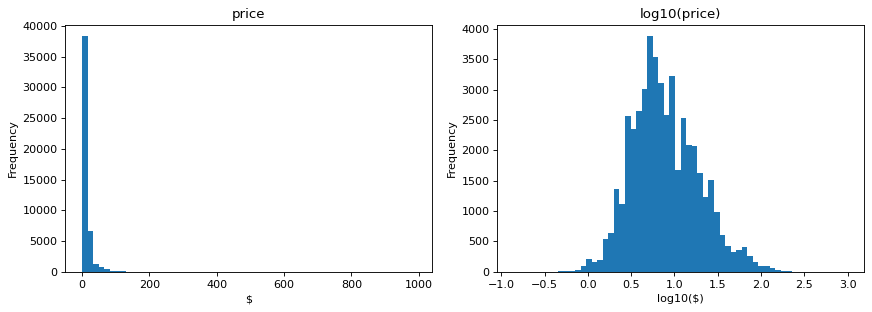

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df['price'].plot.hist(bins=60, ax=axes[0], title='price')
np.log10(df['price']).plot.hist(bins=60, ax=axes[1], title='log10(price)')
axes[0].set_xlabel('$')
axes[1].set_xlabel('log10($)')
plt.tight_layout()
plt.show()

Распределение цены сильно скошено вправо (медиана 7 $, среднее 12.3 $, максимум 990 $). В логарифмической шкале оно близко к нормальному - для статистических методов цену стоит логарифмировать.

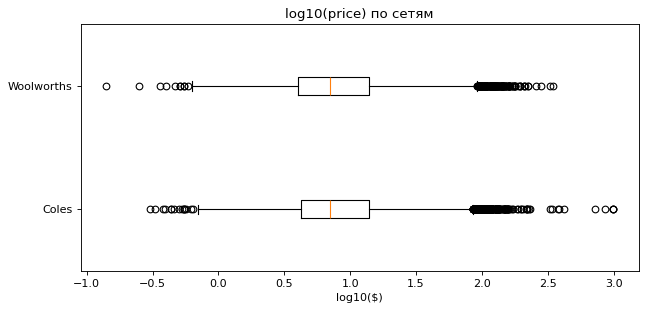

In [32]:
data = [np.log10(df.loc[df['chain'] == c, 'price'].dropna()) for c in ['Coles', 'Woolworths']]
plt.boxplot(data, labels=['Coles', 'Woolworths'], vert=False)
plt.title('log10(price) по сетям')
plt.xlabel('log10($)')
plt.show()

In [33]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({
    'IQR, исходная шкала': {c: iqr_outliers(df[c].dropna()) for c in num_cols},
    'IQR, log-шкала': {c: iqr_outliers(np.log10(df[c].dropna())) for c in num_cols},
})

,"IQR, исходная шкала","IQR, log-шкала"
price,3854,446
was_price,810,20
save_percent,0,35
unit_price,5112,452


По правилу IQR в исходной шкале «выбросами» оказываются тысячи строк - это артефакт скошенного распределения, а не ошибки. В log-шкале их на порядок меньше. Смотрим на крайние значения глазами:

In [34]:
df.nlargest(6, 'price')[['chain', 'name', 'department', 'size', 'price']]

,chain,name,department,size,price
19481,Coles,Grange Shiraz 2017 750ml,Liquorland,1 Each,990.0
19691,Coles,Grange Shiraz 2020 Gift Box 750ml,Liquorland,1 Each,990.0
19984,Coles,Grange Shiraz 2021 750ml,Liquorland,1 Each,990.0
19340,Coles,King George V Scotch Whisky 750ml,Liquorland,1 Each,856.0
19690,Coles,Bin 707 Cabernet Sauvignon 2023 GB 750ml,Liquorland,1 Each,720.0
18529,Coles,Flying Fairy Baijiu 500ml,Liquorland,1 Each,420.0


In [35]:
df.nsmallest(6, 'price')[['chain', 'name', 'size', 'price']]

,chain,name,size,price
25391,Woolworths,Woolworths Bird's Eye Chilli Hot each,each,0.14
25170,Woolworths,Woolworths Reusable Paper Shopping Bag each,each,0.25
13141,Coles,Chicken With Vegetables 6+ Months,120g,0.30
14435,Coles,Lollipop,12g,0.33
23788,Woolworths,Carrot Fresh each,each,0.36
1183,Coles,Murcott Mandarins Medium,approx. 130g each,0.38


Экстремальные цены **реальны**: дорогие вина и виски (Penfolds Grange - 990 $), а самые дешёвые - штучные овощи и пакет за 0.25 $. Удалять их не нужно, это природная вариативность ассортимента.

### 5.2. Цена за единицу - настоящие аномалии

In [36]:
df.nlargest(8, 'unit_price')[['chain', 'name', 'size', 'price', 'unit_price', 'unit_measure']]

,chain,name,size,price,unit_price,unit_measure
15537,Coles,Gentleman Jack Tennessee Whiskey 1l,1 Each,89.0,9500.00,100ml
41957,Woolworths,Swisse Ultiboost High Strength Magnesium Powder Orange 360g,360g,55.0,5500.00,100EA
23478,Coles,Colorstay Micro Hyper Precision Gel Eyeliner Brown,0.06g,26.0,4333.33,10g
46225,Woolworths,Swisse Ultiboost Calcium + D3 + K2 Tablets 60 pack,60 pack,39.5,3950.00,100EA
22522,Coles,Colorstay Micro Brow Pencil Soft Brown,0.09g,25.0,2777.78,10g
22943,Coles,Colorstay Micro Brow Pencil Dark Brown,0.09g,25.0,2777.78,10g
39639,Woolworths,Revlon Colorstay Micro Brow Pencil Soft Brown 0.09g,0.09g,25.0,2777.78,10G
42573,Woolworths,Revlon Colorstay Micro Brow Pencil Dark Brown 0.09g,0.09g,25.0,2777.78,10G


Здесь уже есть **ошибки данных**:
- *Gentleman Jack 1 л* за 89 $ -> `unit_price = 9500` за 100 мл (должно быть 8.90) - ошибка масштаба ×1000;
- *Swisse Magnesium Powder 360g* - единица `100EA` для порошка, 5 500 $ за 100 «штук» - неверная единица;
- косметика и шафран (0.06–0.1 г) - дорого, но **корректно**: пересчёт на 10 г для микрофасовки даёт тысячи долларов.

Вывод: `unit_price` нельзя чистить порогом - нужна проверка согласованности с `price`/`size` (раздел 4.4).

### 5.3. Скидки

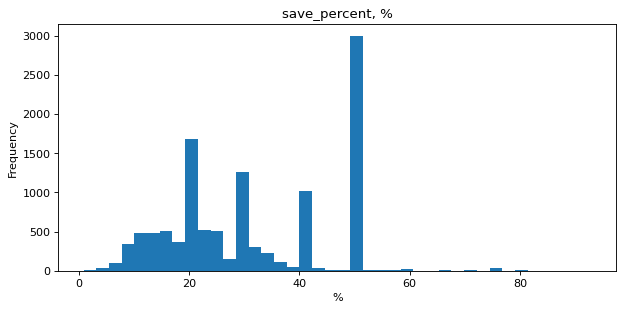

save_percent
50.0    2987
20.0    1287
30.0    1055
40.0     950
25.0     363
21.0     360
10.0     330
22.0     293
Name: count, dtype: int64

In [37]:
df['save_percent'].plot.hist(bins=40, title='save_percent, %')
plt.xlabel('%')
plt.show()
df['save_percent'].round().value_counts().head(8)

Скидки кучкуются на «круглых» значениях (25, 30, 40, 50%) - типичный маркетинговый паттерн, не аномалия. Максимум 92.9% - уценка «REDUCED_TO_CLEAR».

In [38]:
pd.crosstab(df['special_type'].fillna('<NA>'), df['chain'])

chain,Coles,Woolworths
special_type,,
<NA>,19644,25100
MULTI_SAVE,1956,0
PERCENT_OFF,1712,0
REDUCED_TO_CLEAR,437,0
WHILE_STOCKS_LAST,18,0


## 6. Семантический анализ текстовых полей

In [39]:
name_len = df['name'].str.len()
name_len.groupby(df['chain']).describe().round(1)

,count,mean,std,min,25%,50%,75%,max
chain,,,,,,,,
Coles,23767.0,28.7,12.6,2.0,20.0,27.0,36.0,115.0
Woolworths,25100.0,45.2,12.1,12.0,36.0,44.0,53.0,95.0


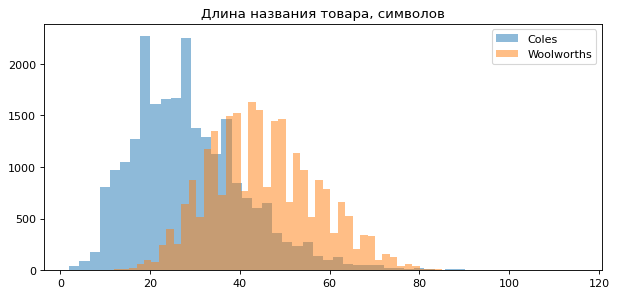

In [40]:
fig, ax = plt.subplots()
for chain in ['Coles', 'Woolworths']:
    ax.hist(name_len[df['chain'] == chain], bins=50, alpha=0.5, label=chain)
ax.set_title('Длина названия товара, символов')
ax.legend()
plt.show()

Названия Woolworths в среднем длиннее: в них есть бренд и фасовка («Heinz Baked Beans 420g x 3 pack»), у Coles — только суть товара. Это подтверждает раздел 3.2.

In [41]:
text_issues = pd.DataFrame({
    'двойные пробелы в name': df['name'].str.contains(r'\s{2,}'),
    'name оканчивается на «...» (обрезан)': df['name'].str.endswith('...'),
    'фасовка в name': df['name'].str.contains(r'\d+\s?(?:g|kg|ml|l)\b', case=False),
}).groupby(df['chain']).sum()
text_issues.T

chain,Coles,Woolworths
двойные пробелы в name,66,34
name оканчивается на «...» (обрезан),0,0
фасовка в name,3173,18559


In [42]:
df.loc[df['name'].str.contains(r'\s{2,}'), 'name'].head()

680                         Soft Drink  Cans Multipack 375mL
831                                           Dry  Can 375ml
872     Sensations Jellies  Favourites Menu Cat Food  12x85g
1400                             Original  Mini Wraps 8 Pack
2170     Entertaining Chicken Tenderlion  Skewer Greek Style
Name: name, dtype: string

Двойные пробелы в названиях Coles - след удалённого бренда («Soft Drink␣␣Cans» <-> «Soft Drink **Pepsi** Cans»). Это потеря информации при парсинге, а не просто форматирование.

In [43]:
size_kind = df['size'].str.lower().str.replace(r'[\d.]+', 'N', regex=True)
size_kind.groupby(df['chain']).value_counts().groupby(level=0).head(6)

chain       size        
Coles       Ng              11210
            N pack           4151
            Nml              3387
            N each           2682
            Nl               1114
            Nkg               873
Woolworths  Ng               9825
            Nml              4327
            N pack           4272
            each             2554
            Nl               1183
            Nml x N pack      958
Name: count, dtype: Int64

Формат `size` у сетей разный: Coles - «1 Each», «approx. 170g», «N Pack»; Woolworths - «each», «Ng», «NmL», «Ng x N pack». Поле нужно парсить в пару (количество, единица) и приводить к единому виду.

In [44]:
df['offer_description'].value_counts().head(10)

offer_description
Get $10 off $100, $20 off $150, $40 off $200 when you shop Liquor. T&Cs apply^^    1607
Designs may vary                                                                    503
Buy 1 get a bonus Container credit^                                                 385
Pick any 2 for $5                                                                   152
Pick any 2 for $7                                                                   141
Pick any 2 for $6                                                                   126
Pick any 2 for $15                                                                  105
Pick any 2 for $20                                                                   98
Pick any 5 for $35                                                                   77
Pick any 2 for $9                                                                    71
Name: count, dtype: int64[pyarrow]

In [45]:
templates = df['offer_description'].dropna().str.replace(r'\$?\d+(?:\.\d+)?', 'N', regex=True)
print('уникальных описаний:', df['offer_description'].nunique(), '→ шаблонов:', templates.nunique())
templates.value_counts().head(8)

уникальных описаний: 1006 → шаблонов: 19


offer_description
Pick any N for N                                                    1876
Get N off N, N off N, N off N when you shop Liquor. T&Cs apply^^    1607
Range was N - N/N/N                                                  767
N for N - N/NG                                                       664
Designs may vary                                                     503
Buy N get a bonus Container credit^                                  385
Was N - N/N/N                                                        308
N for N - N/NL                                                       130
Name: count, dtype: int64[pyarrow]

Около тысячи уникальных описаний акций сводятся к небольшому числу шаблонов («Pick any N for $N», «Was $N - дата»). Из них можно извлечь структурированные признаки (механика, порог, дата). Часть описаний вообще не акции: «Designs may vary», бонус за тару - примечания, а в шаблоне «N for N - N/NG» у Woolworths к механике мультибая приклеена цена за единицу по акции («2 for $5.00 - $31.25/100G»). Поле смешивает разные сущности.

## 7. Корреляции

In [46]:
corr = df[num_cols].corr(method='spearman')
corr.round(2)

,price,was_price,save_percent,unit_price
price,1.00,0.97,-0.04,0.34
was_price,0.97,1.00,0.18,0.34
save_percent,-0.04,0.18,1.00,0.10
unit_price,0.34,0.34,0.10,1.00


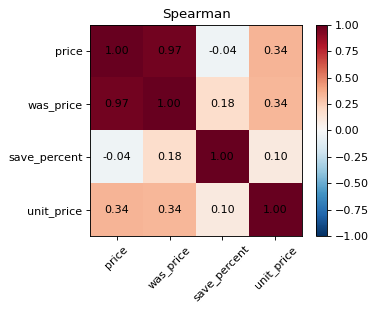

In [47]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45)
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
ax.set_title('Spearman')
plt.tight_layout()
plt.show()

- `price` ↔ `was_price` ≈ 1 - ожидаемо, это избыточная пара, скидка выводится из неё.
- `save_percent` слабо связан с уровнем цены.
- `price` ↔ `unit_price` связаны умеренно: цена за единицу зависит от фасовки и единицы, и сравнивать её корректно только **внутри одной `unit_measure`**.

**Межсетевая проверка.** Сопоставим один и тот же товар в двух сетях по штрих-коду - это независимая проверка достоверности цен.

In [48]:
key = ['barcode', 'name', 'price']
coles = df.loc[df['chain'] == 'Coles', key].dropna()
wool = df.loc[df['chain'] == 'Woolworths', key].dropna()
matched = coles.merge(wool, on='barcode', suffixes=('_coles', '_wool'))

print(f'общих товаров по штрих-коду: {len(matched):,}')
print(f'цена совпадает точно: {(matched.price_coles == matched.price_wool).mean():.1%}')
print(f'корреляция log-цен: {np.corrcoef(np.log(matched.price_coles), np.log(matched.price_wool))[0, 1]:.3f}')
matched.head()

общих товаров по штрих-коду: 9,954
цена совпадает точно: 48.2%
корреляция log-цен: 0.927


,barcode,name_coles,price_coles,name_wool,price_wool
0,9300681169722,Traditional Liquid Gravy Pouch,3.7,Gravox Traditional Liquid Gravy Pouch 165g,3.7
1,9318122387086,Prawn Dumplings,8.5,Hong Kong Dim Sim Kitchen Prawn Dumplings 300g,8.5
2,9300658411076,Yop Yoghurt With Probiotics Strawberry,2.3,Yoplait YOP Yoghurt With Probiotics Strawberry Pouch 130g,2.3
3,9318122389127,Chicken Ginger & Spring Onion Dumpling,8.5,Hong Kong Dim Sim Kitchen Dumplings Chicken Ginger & Spr...,8.5
4,9300658411090,Yop Yoghurt With Probiotics Mango,2.3,Yoplait YOP Yoghurt With Probiotics Mango Pouch 130g,2.3


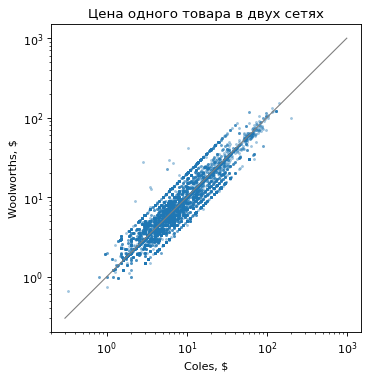

In [49]:
plt.figure(figsize=(5, 5))
plt.scatter(matched['price_coles'], matched['price_wool'], s=3, alpha=0.3)
plt.xscale('log')
plt.yscale('log')
lim = [0.3, 1000]
plt.plot(lim, lim, color='grey', lw=1)
plt.xlabel('Coles, $')
plt.ylabel('Woolworths, $')
plt.title('Цена одного товара в двух сетях')
plt.show()

≈10 тыс. товаров есть в обеих сетях; почти половина стоит одинаково, корреляция log-цен 0.93. Точки вдали от диагонали - либо разные акции в день сбора, либо ошибки (например, разная фасовка под одним штрих-кодом). Это хороший кандидат на автоматическую проверку качества.

## 8. Метрики качества данных

Сведём проверки в метрики по столбцам:
- **Completeness** - доля непустых значений;
- **Uniqueness** - доля уникальных среди непустых;
- **Validity** - доля непустых значений, прошедших правило формата/диапазона.

In [50]:
lower_um = df['unit_measure'].str.lower()
rules = {
    'barcode': df['barcode'].dropna().map(gtin_valid),
    'price': df['price'].dropna() > 0,
    'was_price': (df['was_price'] > df['price'])[df['was_price'].notna()],
    'save_percent': (promo['save_diff'] <= 1),
    'unit_price': (bad.index.to_series().reindex(df['unit_price'].dropna().index).isna()),
    'unit_measure': lower_um.dropna() != '1g',
    'department': df['department'].isin(shared.index),
    'name': ~df['name'].str.contains(r'\s{2,}'),
}

metrics = pd.DataFrame({
    'completeness': df.notna().mean(),
    'uniqueness': df.nunique() / df.notna().sum(),
    'validity': pd.Series({c: r.mean() for c, r in rules.items()}),
}).round(3)
metrics

,completeness,uniqueness,validity
barcode,0.956,0.784,1.000
brand,0.997,0.104,NaN
chain,1.000,0.000,NaN
collected_date,1.000,0.000,NaN
department,1.000,0.001,0.376
image_url,1.000,1.000,NaN
in_stock,1.000,0.000,NaN
name,1.000,0.953,0.998
offer_description,0.139,0.148,NaN
on_special,1.000,0.000,NaN


In [51]:
summary = pd.Series({
    'строк': len(df),
    'полных дублей': int(df.duplicated().sum()),
    'средняя completeness (все столбцы)': metrics['completeness'].mean().round(3),
    'completeness ключевых полей (name, price, department)': df[['name', 'price', 'department']].notna().mean().mean().round(3),
    'строк без цены (не в наличии)': int(df['price'].isna().sum()),
    'согласованность unit_price с price/size': round(1 - len(bad) / len(up), 4),
    'валидных GTIN-13': f"{bc.map(gtin_valid).mean():.0%}",
    'общих отделов у сетей': f'{len(shared)} из {len(dep)}',
})
summary.to_frame('значение')

,значение
строк,48867
полных дублей,0
средняя completeness (все столбцы),0.816
"completeness ключевых полей (name, price, department)",0.993
строк без цены (не в наличии),997
согласованность unit_price с price/size,0.9961
валидных GTIN-13,100%
общих отделов у сетей,8 из 37


Комментарий к таблице: `validity` по `department` - это доля строк в отделах, общих для обеих сетей; она низкая не из-за ошибок, а из-за несовпадающих таксономий. Низкая completeness у `was_price`/`special_type`/`offer_description` структурная (заполняются только у акций).

## 9. Выводы

**Структура.** 48 867 товаров × 20 признаков, по одному магазину Coles и Woolworths, один день сбора. `collected_date` и `store_id` фактически константы - временной и географической динамики в данных нет.

**Целостность.**
- Полных дублей нет; корректный ключ - `(chain, product_id)`. `product_id` пересекается между сетями (33 коллизии).
- Пропуски в основном структурные: цена отсутствует только у товаров не в наличии; акционные поля - только у акций; `brand` пуст у весовых овощей.
- `special_type` у Woolworths не собирается вовсе (100% пропусков), `barcode` у Coles пропущен в 9% строк.

**Согласованность.** Главная проблема датасета - **две сети описаны в разных форматах**:
- `name` у Coles без бренда (и с двойными пробелами на его месте), у Woolworths - с брендом и фасовкой;
- `unit_measure` в разном регистре; у Coles весовые товары помечены `1g` вместо `1kg`;
- 37 отделов, из них общих только 8; есть маркетинговые «псевдоотделы»;
- флаг `on_special` у Coles в 2 300 случаях не подтверждается ни одним полем.

**Выбросы и аномалии.** Экстремальные цены (до 990 $) реальны. Настоящие ошибки найдены в `unit_price` (масштаб ×1000, неверная единица) и `save_percent` (22 строки). `unit_price` согласован с ценой в 99.6% проверяемых строк.

**Ошибка нашего пайплайна.** В `au_supermarket_products.parquet` штрих-коды хранятся как `'…0.0'` и без ведущих нулей - нужно читать CSV с `dtype={'barcode': str}`.

**Рекомендации по очистке (следующий этап):**
1. Исправить чтение `barcode` в `data_loader.py` и пересобрать parquet.
2. Нормализовать `unit_measure` (`lower()`, `1g → 1kg` для весовых Coles).
3. Распарсить `size` в (количество, единица); для Coles дополнить `name` брендом.
4. Построить маппинг `department` → единая категория.
5. Пересчитывать `save_percent` из `price`/`was_price`; флаг аномальных `unit_price` по правилу из раздела 4.4.
6. Для анализа цен исключать строки `in_stock = False` и использовать log-шкалу.

## 10. Расширенная визуализация (Plotly)

Интерактивные графики, которые отображаются на GitHub как статичные PNG.

**Показывает есть ли связь между ценой и размером скидки, различаются ли сети.**

In [52]:
%pip install "nbformat==5.10.4"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


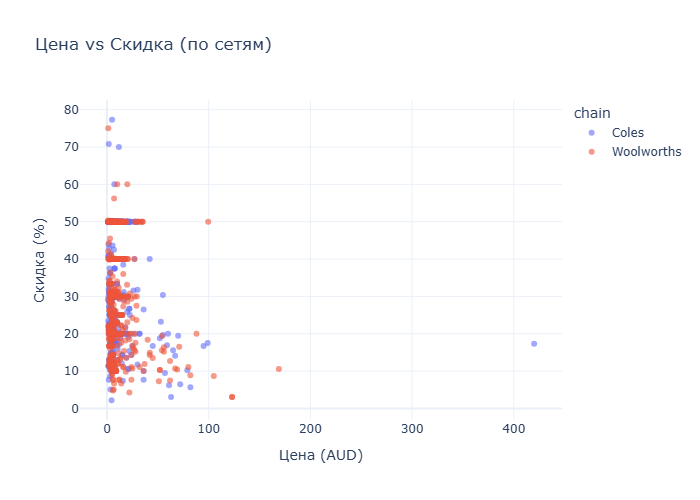

In [53]:
# Scatter: цена vs скидка, цвет - сеть
df_sample = df.dropna(subset=['price', 'save_percent']).sample(1000, random_state=42)

fig = px.scatter(
    df_sample,
    x='price',
    y='save_percent',
    color='chain',
    title='Цена vs Скидка (по сетям)',
    labels={'price': 'Цена (AUD)', 'save_percent': 'Скидка (%)'},
    opacity=0.6
)
fig.show()


** Показывает какие отделы дороже, есть ли выбросы внутри отделов. **

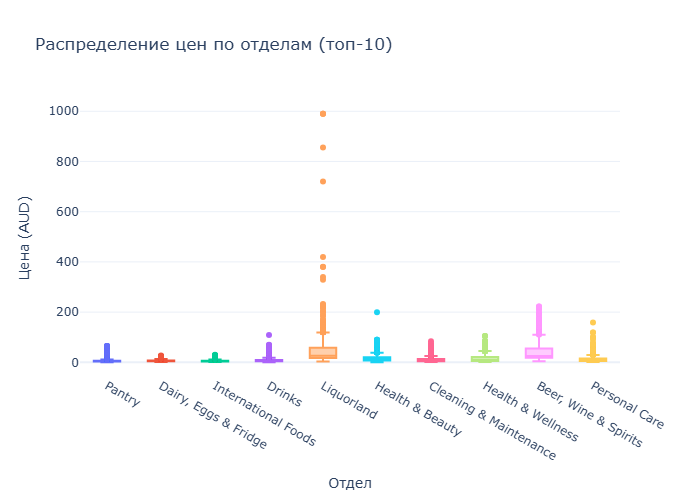

In [54]:
# Box: распределение цен по топ-10 отделам
top_depts = df['department'].value_counts().head(10).index
df_top = df[df['department'].isin(top_depts)]

fig = px.box(
    df_top,
    x='department',
    y='price',
    color='department',
    title='Распределение цен по отделам (топ-10)',
    labels={'price': 'Цена (AUD)', 'department': 'Отдел'}
)
fig.update_layout(showlegend=False)
fig.show()

**Показывает сравнение распределений цен в Coles и Woolworths**

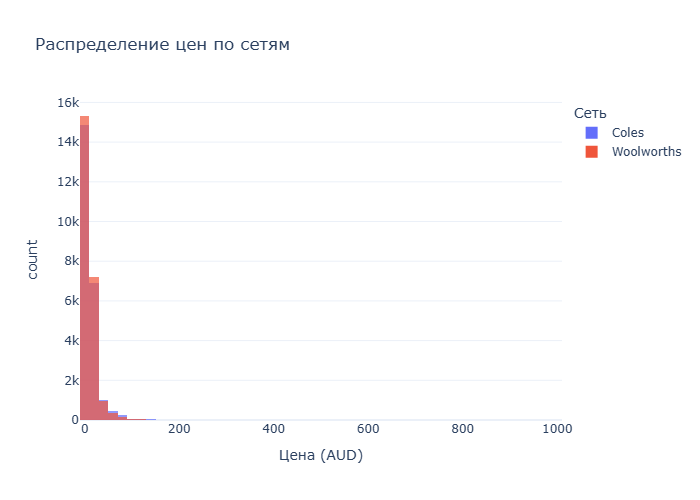

In [55]:
# Histogram: распределение цен с наложением по сетям
fig = px.histogram(
    df,
    x='price',
    color='chain',
    nbins=50,
    title='Распределение цен по сетям',
    labels={'price': 'Цена (AUD)', 'chain': 'Сеть'},
    barmode='overlay',
    opacity=0.7
)
fig.show()

**Показывает какие бренды представлены чаще всего.**

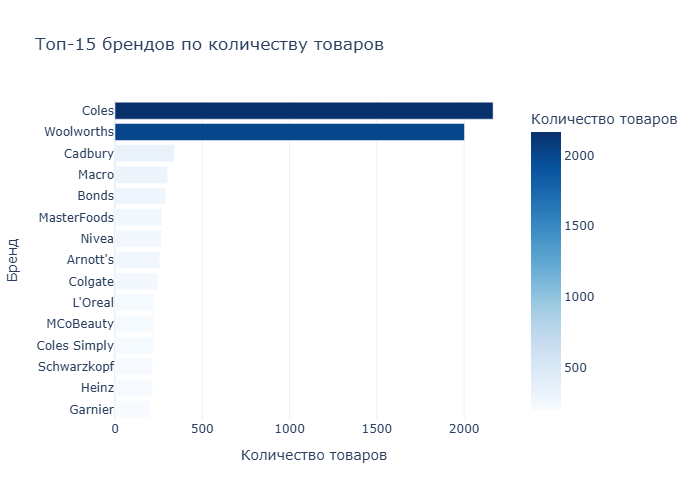

In [56]:
# Bar: топ-15 брендов по количеству товаров
top_brands = df['brand'].value_counts().head(15).reset_index()
top_brands.columns = ['brand', 'count']

fig = px.bar(
    top_brands,
    x='count',
    y='brand',
    orientation='h',
    title='Топ-15 брендов по количеству товаров',
    labels={'count': 'Количество товаров', 'brand': 'Бренд'},
    color='count',
    color_continuous_scale='Blues'
)
fig.update_layout(yaxis={'categoryorder': 'total ascending'})
fig.show()

**Показывает структуру товаров по сетям и отделам, долю товаров на скидке**

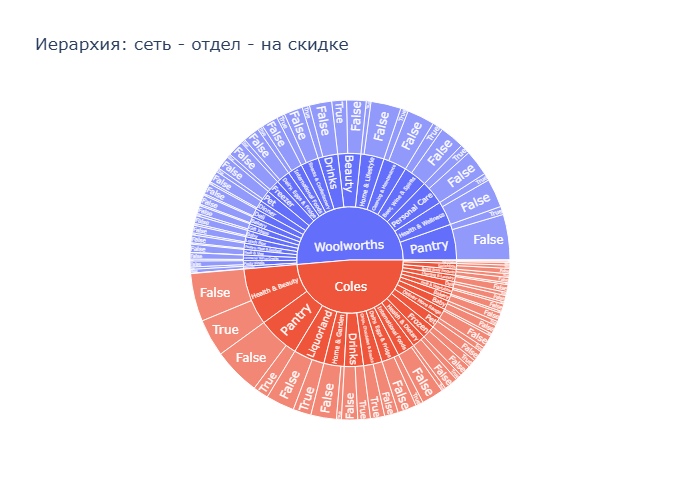

In [57]:
# Sunburst: сеть -> отдел -> on_special
df_sun = df.dropna(subset=['chain', 'department', 'on_special'])
df_sun = df_sun.groupby(['chain', 'department', 'on_special']).size().reset_index(name='count')

fig = px.sunburst(
    df_sun,
    path=['chain', 'department', 'on_special'],
    values='count',
    title='Иерархия: сеть - отдел - на скидке'
)
fig.show()


**Показывает сравнение цен за единицу товара между сетями.**

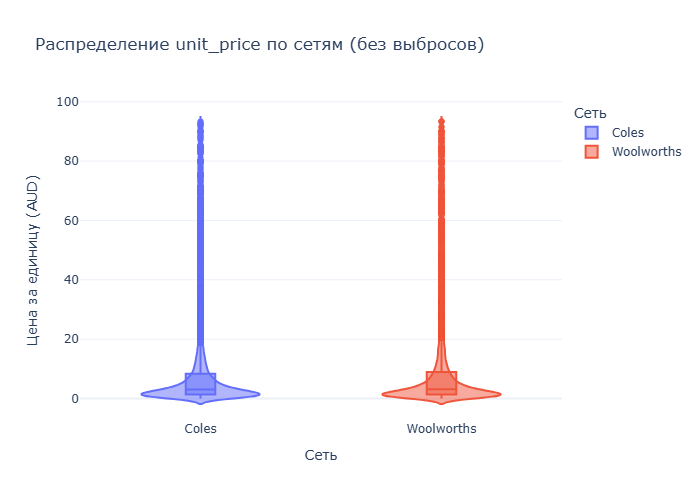

In [59]:
# Violin: unit_price по сетям (без выбросов)
q_high = df['unit_price'].quantile(0.99)
df_violin = df[df['unit_price'] <= q_high]

fig = px.violin(
    df_violin,
    x='chain',
    y='unit_price',
    color='chain',
    box=True,
    title='Распределение unit_price по сетям (без выбросов)',
    labels={'unit_price': 'Цена за единицу (AUD)', 'chain': 'Сеть'}
)
fig.show()

**Выводы по Plotly-визуализации:**

1. **Scatter (цена vs скидка):** связь между ценой и скидкой слабая. Большинство товаров сосредоточено в диапазоне цен до 50 AUD. Заметно, что у Woolworths (красные точки) есть «полка» скидок ровно на 50% (горизонтальная линия), что может указывать на единую маркетинговую акцию или особенность парсинга. Дорогие товары (>100 AUD) почти не имеют скидок.

2. **Box (цены по отделам):** самые дорогие отделы - **Liquorland** (медиана ~50 AUD, выбросы до 990 AUD), **Beer, Wine & Spirits** и **Health & Wellness**. Самые дешевые - **Bakery**, **Dairy** и **Pantry**. В отделе Liquorland наблюдается огромный разброс цен (от 10 до 1000 AUD), что объясняется наличием элитного алкоголя.

3. **Histogram (распределение цен):** цены в обеих сетях распределены похоже - основная масса товаров дешевле 50 AUD. Однако у Coles (синий цвет) заметен «хвост» из дорогих товаров (до 1000 AUD), который у Woolworths выражен слабее.

4. **Bar (бренды):** лидируют собственные торговые марки сетей - **Coles** и **Woolworths** (по ~2000 товаров каждая). Среди внешних брендов выделяются **Cadbury**, **Macro** и **Bonds**. Это подтверждает, что значительная часть ассортимента - это приватные марки супермаркетов.

5. **Sunburst (иерархия):** структура товаров по отделам схожа у обеих сетей. Больше всего товаров на скидке (`on_special = True`) сосредоточено в отделе **Pantry** и **Health & Beauty**. У Coles доля товаров со скидкой визуально выше, чем у Woolworths, что может быть связано с различиями в политике скидок или с тем, как скрапер фиксирует флаг акции.

6. **Violin (unit_price):** медианные значения `unit_price` (цена за единицу) в сетях практически не различаются - основная масса цен за единицу находится в диапазоне до 20 AUD. У Coles (синий) есть длинный «хвост» выбросов до 100 AUD, что связано с дорогими товарами за единицу объема/веса (например, специи или элитный алкоголь).